In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 1000)

sns.set_theme(style="whitegrid")

print("Libraries imported successfully!")

Libraries imported successfully!


In [5]:
import pandas as pd

df = pd.read_csv("attrition_data_.csv")
print("Employee dataset loaded successfully!")
print(df.head())


Employee dataset loaded successfully!
  Employee_ID   Department       City Job_Level Work_Mode  Age  Tenure_Years  Monthly_Salary_INR  Avg_Weekly_Hours  Training_Hours_Last_Year Last_Review_Date  Attrition_Risk_Score
0       E1141  Engineering  Bengaluru    Junior    Remote   24           1.9             36000.0              44.5                      10.0       2025-04-22                  58.7
1       E1100  Engineering      Delhi    Junior    Remote   26           3.2             36000.0              47.8                      30.0       2026-05-11                  66.1
2       E1158        Sales       Pune    Junior    Onsite   27           2.7             29000.0              52.2                      31.0       2025-02-09                  71.4
3       E1053        Sales  Hyderabad    Senior    Onsite   37           2.8            111000.0              48.6                      23.0       2025-01-16                  34.1
4       E1193      Support       Pune       Mid    Hybrid   28

In [6]:
print("Dataset Shape:", df.shape)

print("Number of Rows:", df.shape[0])

print("Number of Columns:", df.shape[1])

Dataset Shape: (255, 12)
Number of Rows: 255
Number of Columns: 12


In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 255 entries, 0 to 254
Data columns (total 12 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Employee_ID               255 non-null    str    
 1   Department                251 non-null    str    
 2   City                      255 non-null    str    
 3   Job_Level                 255 non-null    str    
 4   Work_Mode                 255 non-null    str    
 5   Age                       255 non-null    int64  
 6   Tenure_Years              255 non-null    float64
 7   Monthly_Salary_INR        250 non-null    float64
 8   Avg_Weekly_Hours          249 non-null    float64
 9   Training_Hours_Last_Year  250 non-null    float64
 10  Last_Review_Date          255 non-null    str    
 11  Attrition_Risk_Score      255 non-null    float64
dtypes: float64(5), int64(1), str(6)
memory usage: 24.0 KB


In [8]:
df.describe()

,Age,Tenure_Years,Monthly_Salary_INR,Avg_Weekly_Hours,Training_Hours_Last_Year,Attrition_Risk_Score
count,255.000000,255.000000,250.000000,249.000000,250.000000,255.000000
mean,28.513725,2.505490,60528.000000,45.708032,23.544000,52.328235
std,9.718418,1.356832,31968.533977,5.220302,9.849473,15.820643
min,-27.000000,0.300000,19000.000000,35.000000,0.000000,6.800000
25%,24.000000,1.400000,34000.000000,42.000000,17.000000,40.800000
50%,27.000000,2.300000,52750.000000,45.700000,24.000000,53.500000
75%,32.000000,3.200000,75500.000000,49.300000,30.000000,63.600000
max,142.000000,7.700000,166000.000000,59.800000,57.000000,90.600000


In [9]:
print("Available Columns:")

for column in df.columns:
    print(column)

Available Columns:
Employee_ID
Department
City
Job_Level
Work_Mode
Age
Tenure_Years
Monthly_Salary_INR
Avg_Weekly_Hours
Training_Hours_Last_Year
Last_Review_Date
Attrition_Risk_Score


In [10]:
print("Missing Values in Each Column:")

print(df.isnull().sum())

print("\nTotal Missing Values:")

print(df.isnull().sum().sum())

Missing Values in Each Column:
Employee_ID                 0
Department                  4
City                        0
Job_Level                   0
Work_Mode                   0
Age                         0
Tenure_Years                0
Monthly_Salary_INR          5
Avg_Weekly_Hours            6
Training_Hours_Last_Year    5
Last_Review_Date            0
Attrition_Risk_Score        0
dtype: int64

Total Missing Values:
20


In [11]:
print("Total Duplicate Rows:", df.duplicated().sum())

print("Unique Employee IDs:", df["Employee_ID"].nunique())

Total Duplicate Rows: 5
Unique Employee IDs: 250


In [12]:
df = df.drop_duplicates()

df = df.drop_duplicates(
    subset="Employee_ID",
    keep="first"
)

df = df.reset_index(drop=True)

print("Duplicate records removed successfully!")

print("Updated Dataset Shape:", df.shape)

Duplicate records removed successfully!
Updated Dataset Shape: (250, 12)


In [13]:
category_columns = [
    "Department",
    "City",
    "Job_Level",
    "Work_Mode"
]

for column in category_columns:
    df[column] = df[column].astype("string").str.strip()

df["City"] = df["City"].str.title()

df["Department"] = df["Department"].str.title()
df["Department"] = df["Department"].replace({
    "Hr": "HR"
})

df["Job_Level"] = df["Job_Level"].str.title()

df["Work_Mode"] = df["Work_Mode"].str.title()

print("Categorical data standardized successfully!")

Categorical data standardized successfully!


In [14]:
numeric_columns = [
    "Age",
    "Tenure_Years",
    "Monthly_Salary_INR",
    "Avg_Weekly_Hours",
    "Training_Hours_Last_Year",
    "Attrition_Risk_Score"
]

for column in category_columns:
    most_common = df[column].mode()

    if not most_common.empty:
        df[column] = df[column].fillna(most_common.iloc[0])

for column in numeric_columns:
    df[column] = pd.to_numeric(
        df[column], errors="coerce"
    )

    df[column] = df[column].fillna(
        df[column].median()
    )

print("Missing values handled successfully!")

print("\nRemaining Missing Values:")
print(df.isnull().sum())

Missing values handled successfully!

Remaining Missing Values:
Employee_ID                 0
Department                  0
City                        0
Job_Level                   0
Work_Mode                   0
Age                         0
Tenure_Years                0
Monthly_Salary_INR          0
Avg_Weekly_Hours            0
Training_Hours_Last_Year    0
Last_Review_Date            0
Attrition_Risk_Score        0
dtype: int64


In [15]:
valid_ranges = {
    "Age": (18, 65),
    "Tenure_Years": (0, 45),
    "Monthly_Salary_INR": (10000, 500000),
    "Avg_Weekly_Hours": (0, 100),
    "Training_Hours_Last_Year": (0, 500),
    "Attrition_Risk_Score": (0, 100)
}

for column, limits in valid_ranges.items():

    minimum, maximum = limits

    invalid_values = (
        (df[column] < minimum) |
        (df[column] > maximum)
    )

    df.loc[invalid_values, column] = np.nan

    df[column] = df[column].fillna(
        df[column].median()
    )

print("Invalid numerical values corrected successfully!")

Invalid numerical values corrected successfully!


In [16]:
df["Last_Review_Date"] = pd.to_datetime(
    df["Last_Review_Date"],
    errors="coerce"
)

middle_date = df["Last_Review_Date"].median()

df["Last_Review_Date"] = df["Last_Review_Date"].fillna(
    middle_date
)

print("Date column converted successfully!")

print(df["Last_Review_Date"].dtype)

Date column converted successfully!
datetime64[us]


In [17]:
df["Annual_Salary_INR"] = (
    df["Monthly_Salary_INR"] * 12
)

df["Risk_Category"] = np.select(
    [
        df["Attrition_Risk_Score"] < 40,
        df["Attrition_Risk_Score"] < 70
    ],
    [
        "Low Risk",
        "Medium Risk"
    ],
    default="High Risk"
)

df["Salary_Band"] = pd.cut(
    df["Monthly_Salary_INR"],
    bins=[0, 30000, 50000, 80000, float("inf")],
    labels=[
        "Low Salary",
        "Medium Salary",
        "High Salary",
        "Very High Salary"
    ]
)

print("Additional columns created successfully!")

display(df.head())

Additional columns created successfully!


,Employee_ID,Department,City,Job_Level,Work_Mode,Age,Tenure_Years,Monthly_Salary_INR,Avg_Weekly_Hours,Training_Hours_Last_Year,Last_Review_Date,Attrition_Risk_Score,Annual_Salary_INR,Risk_Category,Salary_Band
0,E1141,Engineering,Bengaluru,Junior,Remote,24.0,1.9,36000.0,44.5,10.0,2025-04-22,58.7,432000.0,Medium Risk,Medium Salary
1,E1100,Engineering,Delhi,Junior,Remote,26.0,3.2,36000.0,47.8,30.0,2026-05-11,66.1,432000.0,Medium Risk,Medium Salary
2,E1158,Sales,Pune,Junior,Onsite,27.0,2.7,29000.0,52.2,31.0,2025-02-09,71.4,348000.0,High Risk,Low Salary
3,E1053,Sales,Hyderabad,Senior,Onsite,37.0,2.8,111000.0,48.6,23.0,2025-01-16,34.1,1332000.0,Low Risk,Very High Salary
4,E1193,Support,Pune,Mid,Hybrid,28.0,4.0,59000.0,42.8,45.0,2026-08-04,40.2,708000.0,Medium Risk,High Salary


In [18]:
os.makedirs("../data/processed", exist_ok=True)

file_path = "../data/processed/employee_attrition_clean.csv"

df.to_csv(
    file_path,
    index=False
)

print("Cleaned dataset saved successfully!")

print("File location:", file_path)

print("File exists:", os.path.exists(file_path))

Cleaned dataset saved successfully!
File location: ../data/processed/employee_attrition_clean.csv
File exists: True


In [19]:
print("=" * 45)
print("EMPLOYEE ATTRITION ANALYSIS")
print("=" * 45)

print("\nAverage Attrition Risk:")
print(round(df["Attrition_Risk_Score"].mean(), 2))

print("\nMaximum Attrition Risk:")
print(df["Attrition_Risk_Score"].max())

print("\nMinimum Attrition Risk:")
print(df["Attrition_Risk_Score"].min())

print("\nRisk Category Distribution:")
print(df["Risk_Category"].value_counts())

EMPLOYEE ATTRITION ANALYSIS

Average Attrition Risk:
52.24

Maximum Attrition Risk:
90.6

Minimum Attrition Risk:
6.8

Risk Category Distribution:
Risk_Category
Medium Risk    157
Low Risk        58
High Risk       35
Name: count, dtype: int64


In [20]:
department_comparison = df.groupby(
    "Department"
)["Attrition_Risk_Score"].mean().round(2)

print("Average Attrition Risk by Department:")

display(department_comparison)

Average Attrition Risk by Department:


Department
Engineering    51.83
Finance        50.52
HR             53.47
Sales          54.86
Support        50.92
Name: Attrition_Risk_Score, dtype: float64

In [22]:
work_comparison = df.groupby(
    "Work_Mode"
)["Attrition_Risk_Score"].mean().round(2)

print("Average Attrition Risk by Work Mode:")

display(work_comparison)

Average Attrition Risk by Work Mode:


Work_Mode
Hybrid    51.50
Onsite    53.96
Remote    50.33
Name: Attrition_Risk_Score, dtype: float64

In [23]:
job_comparison = df.groupby(
    "Job_Level"
)["Attrition_Risk_Score"].mean().round(2)

print("Average Attrition Risk by Job Level:")

display(job_comparison)

Average Attrition Risk by Job Level:


Job_Level
Junior    59.39
Mid       50.75
Senior    35.77
Name: Attrition_Risk_Score, dtype: float64

In [24]:
correlation = df[numeric_columns].corr()

print("Correlation Matrix:")

display(correlation.round(2))

print("\nCorrelation with Attrition Risk:")

display(
    correlation["Attrition_Risk_Score"].sort_values(
        ascending=False
    ).round(2)
)

Correlation Matrix:


,Age,Tenure_Years,Monthly_Salary_INR,Avg_Weekly_Hours,Training_Hours_Last_Year,Attrition_Risk_Score
Age,1.00,0.37,0.75,-0.06,-0.06,-0.45
Tenure_Years,0.37,1.00,0.30,-0.02,-0.05,-0.20
Monthly_Salary_INR,0.75,0.30,1.00,-0.06,-0.12,-0.56
Avg_Weekly_Hours,-0.06,-0.02,-0.06,1.00,-0.00,0.51
Training_Hours_Last_Year,-0.06,-0.05,-0.12,-0.00,1.00,0.01
Attrition_Risk_Score,-0.45,-0.20,-0.56,0.51,0.01,1.00



Correlation with Attrition Risk:


Attrition_Risk_Score        1.00
Avg_Weekly_Hours            0.51
Training_Hours_Last_Year    0.01
Tenure_Years               -0.20
Age                        -0.45
Monthly_Salary_INR         -0.56
Name: Attrition_Risk_Score, dtype: float64

In [25]:
os.makedirs("../images", exist_ok=True)

print("Images folder is ready!")

Images folder is ready!


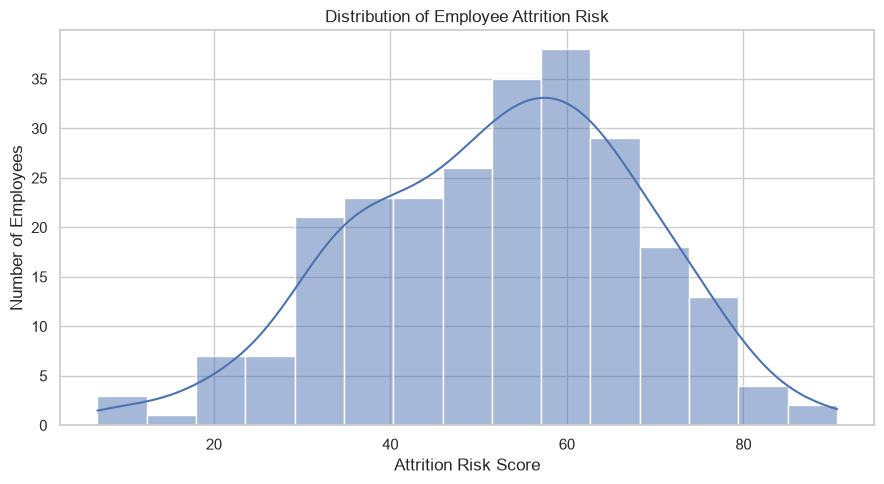

In [26]:
plt.figure(figsize=(9, 5))

sns.histplot(
    data=df,
    x="Attrition_Risk_Score",
    bins=15,
    kde=True
)

plt.title("Distribution of Employee Attrition Risk")
plt.xlabel("Attrition Risk Score")
plt.ylabel("Number of Employees")

plt.tight_layout()

plt.savefig("../images/01_risk_distribution.png")

plt.show()

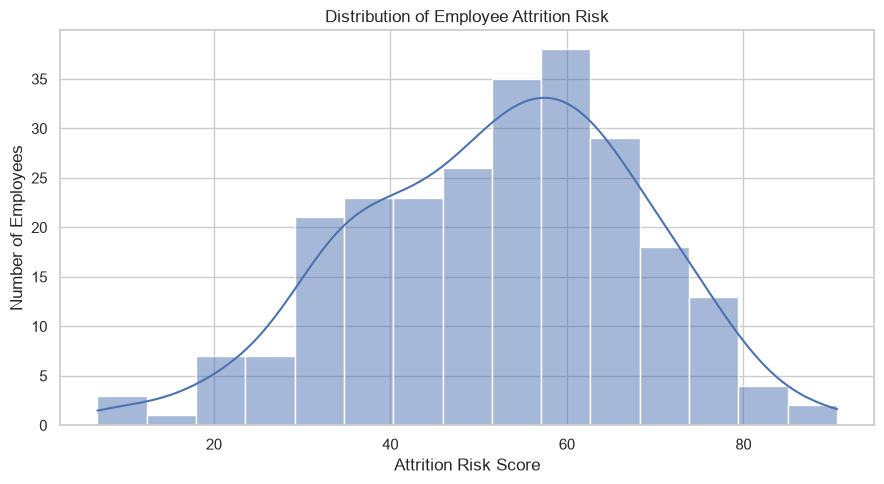

In [27]:
plt.figure(figsize=(9, 5))

sns.histplot(
    data=df,
    x="Attrition_Risk_Score",
    bins=15,
    kde=True
)

plt.title("Distribution of Employee Attrition Risk")
plt.xlabel("Attrition Risk Score")
plt.ylabel("Number of Employees")

plt.tight_layout()

plt.savefig("../images/01_risk_distribution.png")

plt.show()

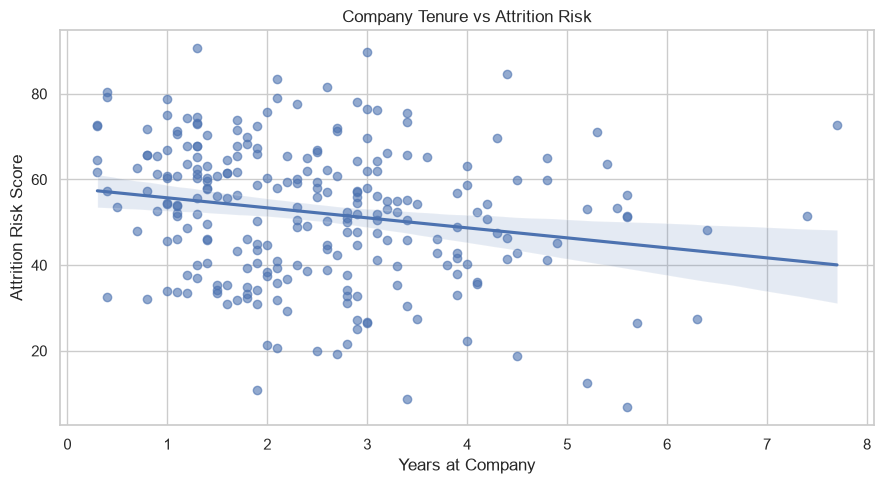

In [28]:
plt.figure(figsize=(9, 5))

sns.regplot(
    data=df,
    x="Tenure_Years",
    y="Attrition_Risk_Score",
    scatter_kws={"alpha": 0.6}
)

plt.title("Company Tenure vs Attrition Risk")
plt.xlabel("Years at Company")
plt.ylabel("Attrition Risk Score")

plt.tight_layout()

plt.savefig("../images/03_tenure_risk.png")

plt.show()

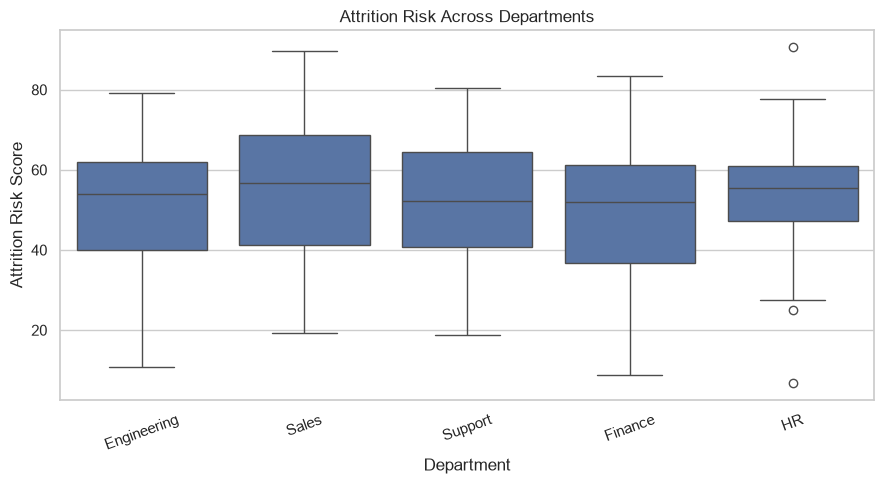

In [29]:
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df,
    x="Department",
    y="Attrition_Risk_Score"
)

plt.title("Attrition Risk Across Departments")
plt.xlabel("Department")
plt.ylabel("Attrition Risk Score")

plt.xticks(rotation=20)

plt.tight_layout()

plt.savefig("../images/04_department_risk.png")

plt.show()

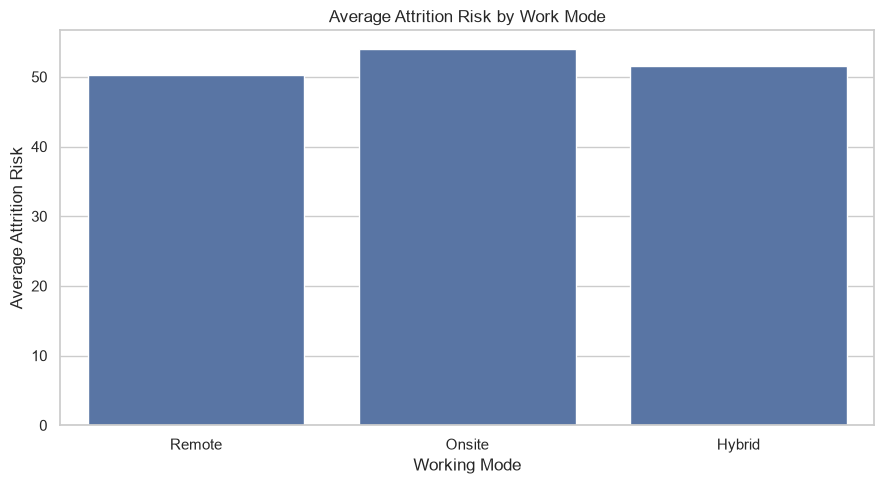

In [30]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=df,
    x="Work_Mode",
    y="Attrition_Risk_Score",
    errorbar=None
)

plt.title("Average Attrition Risk by Work Mode")
plt.xlabel("Working Mode")
plt.ylabel("Average Attrition Risk")

plt.tight_layout()

plt.savefig("../images/05_work_mode.png")

plt.show()

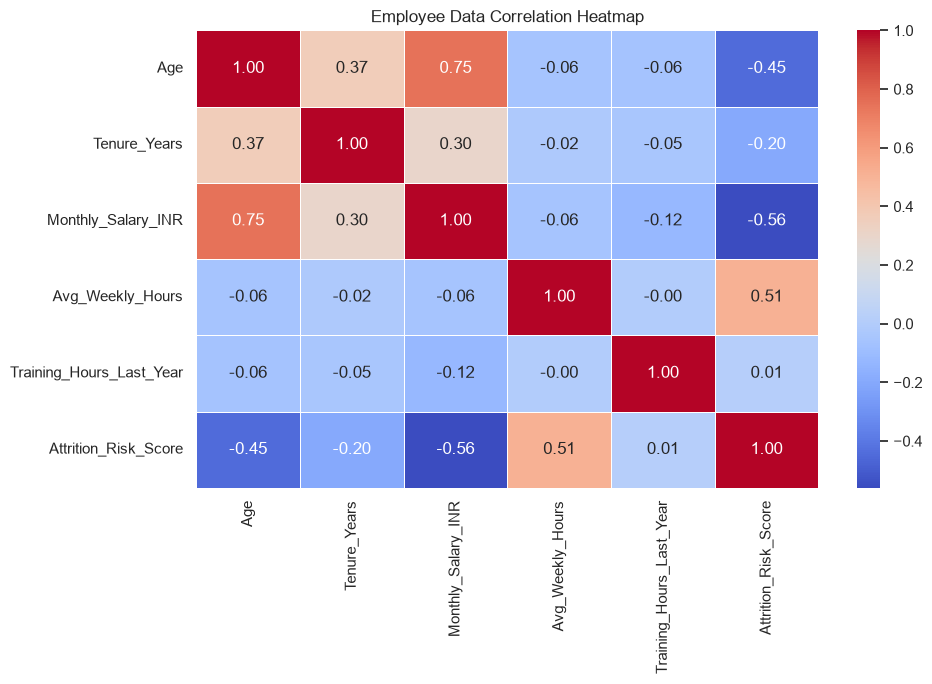

In [31]:
plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Employee Data Correlation Heatmap")

plt.tight_layout()

plt.savefig("../images/06_correlation_heatmap.png")

plt.show()

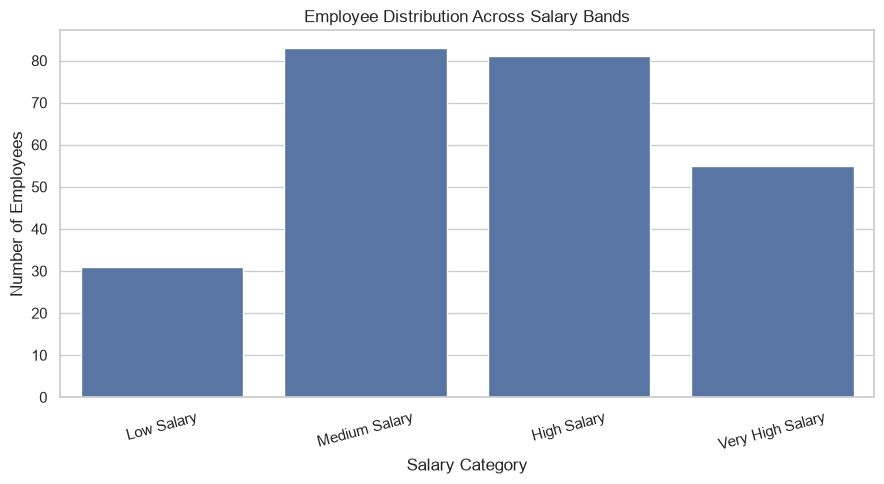

In [32]:
plt.figure(figsize=(9, 5))

sns.countplot(
    data=df,
    x="Salary_Band"
)

plt.title("Employee Distribution Across Salary Bands")
plt.xlabel("Salary Category")
plt.ylabel("Number of Employees")

plt.xticks(rotation=15)

plt.tight_layout()

plt.savefig("../images/07_salary_distribution.png")

plt.show()

In [33]:
high_risk_employees = df[
    df["Attrition_Risk_Score"] >= 70
]

print("Employees Requiring Attention:")

display(
    high_risk_employees[
        [
            "Employee_ID",
            "Department",
            "Job_Level",
            "Attrition_Risk_Score",
            "Risk_Category"
        ]
    ]
)

total_high_risk = len(high_risk_employees)

percentage = (
    total_high_risk / len(df)
) * 100

print("\nTotal High-Risk Employees:")
print(total_high_risk)

print("\nPercentage of High-Risk Employees:")
print(round(percentage, 2), "%")

Employees Requiring Attention:


,Employee_ID,Department,Job_Level,Attrition_Risk_Score,Risk_Category
2,E1158,Sales,Junior,71.4,High Risk
7,E1106,Sales,Junior,75.6,High Risk
11,E1005,Finance,Mid,76.4,High Risk
13,E1184,Engineering,Junior,71.9,High Risk
17,E1153,Sales,Junior,73.9,High Risk
28,E1243,HR,Mid,90.6,High Risk
40,E1137,Engineering,Junior,79.3,High Risk
51,E1238,Support,Junior,72.0,High Risk
53,E1129,Sales,Mid,71.6,High Risk
57,E1220,Sales,Junior,70.6,High Risk



Total High-Risk Employees:
35

Percentage of High-Risk Employees:
14.0 %


In [37]:
high_risk_employees.to_csv(
    "../data/processed/high_risk_employees.csv",
    index=False
)

print("High-risk employee report saved successfully!")

High-risk employee report saved successfully!


In [39]:
import os

file_path = "../data/processed/employee_attrition_clean.csv"

df_clean = pd.read_csv(file_path)

print("=" * 45)
print("FINAL PROJECT DATA VERIFICATION")
print("=" * 45)

print("\nDataset Shape:")
print(df_clean.shape)

print("\nDuplicate Records:")
print(df_clean.duplicated().sum())

print("\nMissing Values:")
print(df_clean.isnull().sum().sum())

print("\nColumn Names:")
print(df_clean.columns.tolist())

print("\nData Types:")
print(df_clean.dtypes)

print("\nFirst Five Records:")
display(df_clean.head())

print("\nCleaned File Exists:")
print(os.path.exists(file_path))

print("\nFinal Verification Completed!")

FINAL PROJECT DATA VERIFICATION

Dataset Shape:
(250, 15)

Duplicate Records:
0

Missing Values:
0

Column Names:
['Employee_ID', 'Department', 'City', 'Job_Level', 'Work_Mode', 'Age', 'Tenure_Years', 'Monthly_Salary_INR', 'Avg_Weekly_Hours', 'Training_Hours_Last_Year', 'Last_Review_Date', 'Attrition_Risk_Score', 'Annual_Salary_INR', 'Risk_Category', 'Salary_Band']

Data Types:
Employee_ID                     str
Department                      str
City                            str
Job_Level                       str
Work_Mode                       str
Age                         float64
Tenure_Years                float64
Monthly_Salary_INR          float64
Avg_Weekly_Hours            float64
Training_Hours_Last_Year    float64
Last_Review_Date                str
Attrition_Risk_Score        float64
Annual_Salary_INR           float64
Risk_Category                   str
Salary_Band                     str
dtype: object

First Five Records:


,Employee_ID,Department,City,Job_Level,Work_Mode,Age,Tenure_Years,Monthly_Salary_INR,Avg_Weekly_Hours,Training_Hours_Last_Year,Last_Review_Date,Attrition_Risk_Score,Annual_Salary_INR,Risk_Category,Salary_Band
0,E1141,Engineering,Bengaluru,Junior,Remote,24.0,1.9,36000.0,44.5,10.0,2025-04-22,58.7,432000.0,Medium Risk,Medium Salary
1,E1100,Engineering,Delhi,Junior,Remote,26.0,3.2,36000.0,47.8,30.0,2026-05-11,66.1,432000.0,Medium Risk,Medium Salary
2,E1158,Sales,Pune,Junior,Onsite,27.0,2.7,29000.0,52.2,31.0,2025-02-09,71.4,348000.0,High Risk,Low Salary
3,E1053,Sales,Hyderabad,Senior,Onsite,37.0,2.8,111000.0,48.6,23.0,2025-01-16,34.1,1332000.0,Low Risk,Very High Salary
4,E1193,Support,Pune,Mid,Hybrid,28.0,4.0,59000.0,42.8,45.0,2026-08-04,40.2,708000.0,Medium Risk,High Salary



Cleaned File Exists:
True

Final Verification Completed!
